In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_csv("/content/Salary_Data.csv")
df

,YearsExperience,Salary
0,1.1,39343.0
1,1.3,46205.0
2,1.5,37731.0
3,2.0,43525.0
4,2.2,39891.0
5,2.9,56642.0
6,3.0,60150.0
7,3.2,54445.0
8,3.2,64445.0
9,3.7,57189.0


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.isna().sum()

,0
YearsExperience,0
Salary,0


In [ ]:
x = df.drop(columns='Salary')
x.ndim

2

In [ ]:
y = df['Salary']
y.ndim

1

In [ ]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x,y, test_size=0.30, random_state=42)

<Axes: xlabel='YearsExperience', ylabel='Salary'>

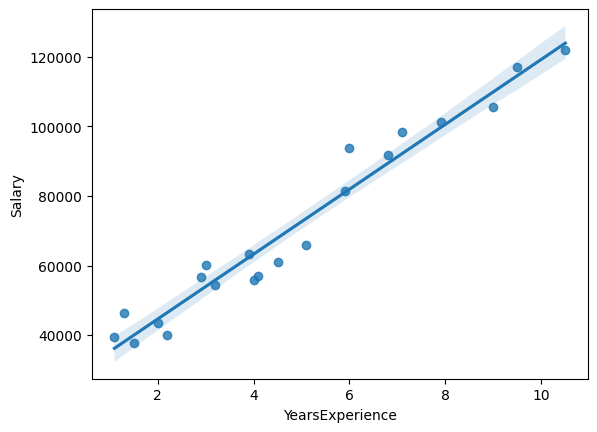

In [ ]:
sns.regplot(x=x_train,y=y_train)

In [ ]:
from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(x_train, y_train)

LinearRegression()

In [ ]:
y_pred = model.predict(x_test)
y_pred

array([115573.62288352,  71679.93878159, 102498.90847018,  75415.57147111,
        55803.4998511 ,  60473.04071301, 122110.98009019, 107168.44933209,
        63274.76523015])

In [ ]:
y_test.values

array([112635.,  67938., 113812.,  83088.,  64445.,  57189., 122391.,
       109431.,  56957.])

In [ ]:
print(model.predict([[3.2]]))

[55803.4998511]


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


In [ ]:
print(model.predict([[3.5]]))

[58605.22436825]


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


In [ ]:
# actual value, predict_value, error = actual - predict value --> df

e = pd.DataFrame({
    "actual_value": y_test,
    "predicted_value": y_pred,
    "error": y_test - y_pred
})

In [ ]:
e

,actual_value,predicted_value,error
27,112635.0,115573.622884,-2938.622884
15,67938.0,71679.938782,-3741.938782
23,113812.0,102498.908470,11313.091530
17,83088.0,75415.571471,7672.428529
8,64445.0,55803.499851,8641.500149
9,57189.0,60473.040713,-3284.040713
28,122391.0,122110.980090,280.019910
24,109431.0,107168.449332,2262.550668
12,56957.0,63274.765230,-6317.765230


In [ ]:
# y = mx + c
print('Slope is', model.coef_)
print('Constant is', model.intercept_)

Slope is [9339.08172382]
Constant is 25918.438334893202


#**Performance Evaluation in Regression**

**MAE** --> Mean Absolute Error

**MAPE** --> Mean Absolute Perfect Square

**MSE** --> Mean Square Error

**RMSE** --> Root Mean Square Error

**r2_score**

 * y : actual value

 * y^ : predicted value

 **MAE --> Mean Absolute Error**

 * error = y-y^

 * absolute error = |y-y^|

 * mean absolute error = 1/n Σ |y-y^|

**MAPE --> Mean Absolute Perfect Square**   

* Total Percentage of MAE

**MSE --> Mean Square Error**

* error = y-y^

* sq error = (y-y^)^2

* mse = (y-y^)^2/n

**RMSE --> Root Mean Square Error**

root of mse

**MAE**

In [ ]:
from sklearn.metrics import mean_absolute_error
mae = mean_absolute_error(y_test,y_pred)
mae

5161.328710400183

**MAPE**

In [ ]:
from sklearn.metrics import mean_absolute_percentage_error
mape = mean_absolute_percentage_error(y_test, y_pred)
mape

0.06647907533756252

**MSE**

In [ ]:
from sklearn.metrics import mean_squared_error
mse = mean_squared_error(y_test, y_pred)
mse

37784662.46621314

**RMSE**

In [ ]:
from sklearn.metrics import root_mean_squared_error
rmse = root_mean_squared_error(y_test, y_pred)
rmse

6146.92300799458

**r2_score**

In [ ]:
from sklearn.metrics import r2_score
score = r2_score(y_test, y_pred)
score

0.9414466227178214